# Panels with a T-stiffener modeled as multi-domain assemblies

This example analyses a laminated panel with one T-stiffener that has a debonding defect between its base and the skin. It covers linear buckling, free vibration and panel flutter.

Following Castro and Donadon (2017), the skin, the base and the flange of the stiffener are 2D domains (`Shell` objects) connected along their edges and, between skin and base, over their common area. The skin is divided along $x$ into three regions: below, at and above the defect. Along the defect of length `defect_a` (a fraction of $a$) at the middle of the panel, the base is not connected to the skin. The connections are imposed with penalty stiffnesses, `conn_method='penalty'`, or exactly, `conn_method='null-space'`, see [Exact connections with the null-space method](../multidomain_null_space.rst).

The assembly functions `tstiff2d_1stiff_compression`, `tstiff2d_1stiff_freq` and `tstiff2d_1stiff_flutter` build the assembly and run the analysis. They return the assembly, with the domains in the groups `'skin'`, `'base'` and `'flange'`, the eigenvalues and the eigenvectors.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from panels.multidomain import (tstiff2d_1stiff_compression,
                                tstiff2d_1stiff_freq, tstiff2d_1stiff_flutter)


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))


def plot_skin(md, c, ax, title=''):
    """Contour of w on the skin domains, x along the horizontal axis"""
    panels = [p for p in md.panels if p.group == 'skin']
    res = md.uvw(np.real(c), 'skin', gridx=30, gridy=30)
    vmax = max(np.abs(f).max() for f in res['w'])
    levels = np.linspace(-vmax, vmax, 31)
    for p, x, y, f in zip(panels, res['x'], res['y'], res['w']):
        ax.contourf(x + p.x0, y + p.y0, f, levels=levels, cmap='coolwarm')
    ax.set_xlabel('$x$ (m)')
    ax.set_ylabel('$y$ (m)')
    ax.set_title(title)
    ax.set_aspect('equal')

## Panel

The flat skin is $a = 3$ m long and $b = 1$ m wide, with the laminate $[0/45/-45/90/-45/45/0]$. The stiffener lies at $y_s = b/2$, with a base of width $b_b = b/5$, $[0/90/0]_4$, and a flange of height $b_f = b_b/2$, $[0/90/0]_8$. All plies are carbon/epoxy, 0.125 mm thick, with density 1300 kg/m³. The skin domains have $m \times n$ terms, the base $m_b \times n_b$ and the flange $m_f \times n_f$.

In [2]:
common = dict(b=1., bb=0.2, bf=0.1, a=3., ys=0.5, rho=1.3e3, plyt=0.125e-3,
              laminaprop=(142.5e9, 8.7e9, 0.28, 5.1e9, 5.1e9, 5.1e9),
              stack_skin=[0, 45, -45, 90, -45, 45, 0],
              stack_base=[0, 90, 0]*4, stack_flange=[0, 90, 0]*8)
results = {}

## Linear buckling

The panel is compressed by `Nxx` = -1 N/m in the skin, the base and the flange, with a defect of $0.6 a$. The load multiplier $\lambda$ is the critical $N_{xx}$ in N/m. With `run_static_case=False` the pre-buckling stress is the constant `Nxx` of each domain. With `run_static_case=True` it comes from a linear static analysis, which also returns its Ritz constants.

critical Nxx: constant 142.681 N/m, from static 114.854 N/m


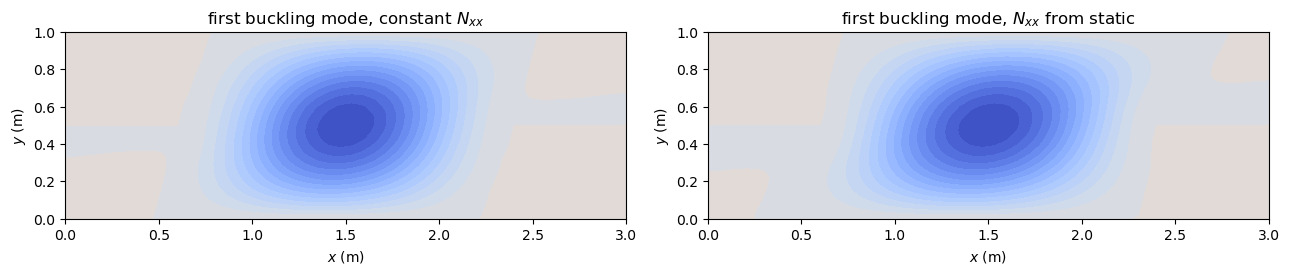

In [3]:
loads = dict(Nxx_skin=-1., Nxx_base=-1., Nxx_flange=-1., defect_a=0.6,
             m=8, n=7, mb=7, nb=6, mf=8, nf=6, num_eigvalues=10,
             conn_method='penalty')
md, eigvals, eigvecs = tstiff2d_1stiff_compression(run_static_case=False,
                                                   **loads, **common)
results['buckling, constant Nxx'] = eigvals[0]
mode_cte = (md, eigvecs[:, 0])
md, c, eigvals, eigvecs = tstiff2d_1stiff_compression(run_static_case=True,
                                                      **loads, **common)
results['buckling, Nxx from static'] = eigvals[0]
mode_static = (md, eigvecs[:, 0])
print('critical Nxx: constant %.3f N/m, from static %.3f N/m'
      % (results['buckling, constant Nxx'],
         results['buckling, Nxx from static']))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
plot_skin(*mode_cte, axes[0], 'first buckling mode, constant $N_{xx}$')
plot_skin(*mode_static, axes[1], 'first buckling mode, $N_{xx}$ from static')
fig.tight_layout()
plt.show()

## Free vibration

With a defect of $0.1 a$, `tstiff2d_1stiff_freq` solves $(\boldsymbol{K}_C + \lambda^2 \boldsymbol{M})\boldsymbol{c} = \boldsymbol{0}$, with $\lambda^2 = -\omega_n^2$. The first natural frequency $\omega_n$ is in rad/s. Both connection methods are used; the penalty method, with the default penalty constants, gives a slightly lower frequency.

penalty   : first natural frequency 48.2733 rad/s


null-space: first natural frequency 48.3875 rad/s


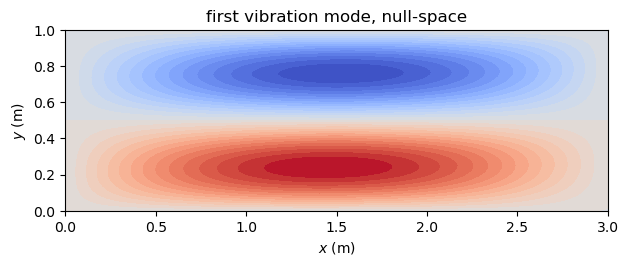

In [4]:
terms = dict(defect_a=0.1, m=6, n=7, mb=5, nb=6, mf=6, nf=7, num_eigvalues=10)
for method in ('penalty', 'null-space'):
    md, eigvals, eigvecs = tstiff2d_1stiff_freq(conn_method=method, **terms,
                                                **common)
    results['frequency, %s' % method] = np.sqrt(-eigvals[0]).real
    print('%-10s: first natural frequency %.4f rad/s'
          % (method, results['frequency, %s' % method]))
    if method == 'null-space':
        mode_freq = (md, eigvecs[:, 0])
fig, ax = plt.subplots(figsize=(7, 3))
plot_skin(*mode_freq, ax, 'first vibration mode, null-space')
plt.show()

## Flutter

`tstiff2d_1stiff_flutter` adds the aerodynamic stiffness of the linear piston theory for a flow along $x$ at Mach 2, speed $2 \times 343$ m/s and air density 1.2 kg/m³. It solves $(\boldsymbol{K}_C + \boldsymbol{K}_A + \lambda^2 \boldsymbol{M})\boldsymbol{c} = \boldsymbol{0}$, see [Aeroelasticity](../aeroelasticity.rst). $\boldsymbol{K}_A$ is not symmetric, and pairs of complex conjugate eigenvalues appear where two modes have coalesced.

In [5]:
md, eigvals, eigvecs = tstiff2d_1stiff_flutter(
    air_speed=2*343., rho_air=1.2, Mach=2, speed_sound=343.,
    run_static_case=False, conn_method='penalty', **terms, **common)
print('eigenvalues lambda^2:')
for ev in eigvals:
    print('  %14.2f %+14.2fj' % (ev.real, ev.imag))
results['flutter, first eigenvalue'] = np.sqrt(-eigvals[0]).real

eigenvalues lambda^2:
      -199018.86          -0.00j
      -231513.15     +141285.16j
      -231513.15     -141285.16j
      -238221.51     +276499.68j
      -238849.23     +275251.96j
      -238849.23     -275251.96j
      -238221.51     -276499.68j
      -359447.26          -0.00j
      -356074.32     +274514.43j
      -356074.32     -274514.43j


## Results

The reference values are regression values of the panels unit tests `tests/multidomain/test_tstiff2d_assembly.py` (penalty), checked there within 0.1%, and `tests/multidomain/test_null_space.py` (null-space), checked within $10^{-5}$. No literature value is available for these configurations.

In [6]:
REF = {'buckling, constant Nxx': (142.68, '`test_tstiff2d_assembly.py`'),
       'buckling, Nxx from static': (114.86, '`test_tstiff2d_assembly.py`'),
       'frequency, penalty': (48.2733, '`test_tstiff2d_assembly.py`'),
       'frequency, null-space': (48.3875, '`test_null_space.py`'),
       'flutter, first eigenvalue': (446.12, '`test_tstiff2d_assembly.py`')}
UNITS = {'buckling': 'critical $N_{xx}$ (N/m)', 'frequency': '$\\omega_n$ (rad/s)',
         'flutter': '$\\sqrt{-\\lambda^2_1}$ (rad/s)'}
results_table([('%s, %s' % (key, UNITS[key.split(',')[0]]), results[key], ref,
                'regression value, %s' % src)
               for key, (ref, src) in REF.items()])

| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| buckling, constant Nxx, critical $N_{xx}$ (N/m) | 142.681 | 142.68 | +7.77e-06 | regression value, `test_tstiff2d_assembly.py` |
| buckling, Nxx from static, critical $N_{xx}$ (N/m) | 114.854 | 114.86 | -4.95e-05 | regression value, `test_tstiff2d_assembly.py` |
| frequency, penalty, $\omega_n$ (rad/s) | 48.2733 | 48.2733 | -6.80e-07 | regression value, `test_tstiff2d_assembly.py` |
| frequency, null-space, $\omega_n$ (rad/s) | 48.3875 | 48.3875 | +5.21e-07 | regression value, `test_null_space.py` |
| flutter, first eigenvalue, $\sqrt{-\lambda^2_1}$ (rad/s) | 446.115 | 446.12 | -1.05e-05 | regression value, `test_tstiff2d_assembly.py` |

## References

1. S. G. P. Castro and M. V. Donadon, "Assembly of semi-analytical models to address linear buckling and vibration of stiffened composite panels with debonding defect". Composite Structures, 160:232-247, 2017. https://doi.org/10.1016/j.compstruct.2016.10.026.